### Opzet van de test
___
> In 06_Dataprep vullen we gaten in met een methode per gatlengte: **lineair** voor korte gaten, **Kalman smoother** voor middellange gaten en **LightGBM** voor gaten tot 1 dag. Dit notebook test of dat ook echt de beste keuzes zijn
>
> We halen op 3 plekken bewust echte metingen weg, laten 8 methodes de gaten invullen en vergelijken de uitkomst daarna met de echte waarden

| Test-gat | Lengte | Onze keuze in 06_Dataprep |
|---|---|---|
| Gat 1 | 1 tijdvak (5 minuten) | Linear |
| Gat 2 | 6 tijdvakken (30 minuten) | Kalman smoother |
| Gat 3 | 1 dag (288 tijdvakken) | LightGBM |

**Methodes die getest worden**

| # | Methode | Idee |
|---|---|---|
| 2.1 | Mean | Gemiddelde van de hele reeks |
| 2.2 | Linear | Rechte lijn tussen de meting vóór en ná het gat |
| 2.3 | Forward fill | Laatste meting vóór het gat herhalen |
| 2.4 | Moving average | Gemiddelde van de metingen rondom het gat |
| 2.6 | Kalman filter | Dagpatroon + niveau, alleen met data van vóór het gat |
| 2.7 | Kalman smoother | Dagpatroon + niveau, met data van vóór én ná het gat |
| 2.8 | LightGBM | Machine learning op tijd en eerdere dagen |
| 2.9 | Seasonal naive | Waarde van precies 24 uur eerder (eigen toevoeging) |

**Opbouw**

> 1. Data klaarzetten en automatisch 3 test-gaten kiezen
> 2. Elke methode vult de 3 gaten in. Per methode zie je alleen de schatting, nog niet de echte waarde
> 3. Pas daarna gaat de echte data eroverheen en worden de fouten (MAE en RMSE) vergeleken
> 4. Dezelfde test in rondes op tientallen willekeurige gaten per lengte, zodat de uitslag niet van één toevallig gat afhangt
>
> Elke methode houdt in het hele notebook dezelfde kleur. De echte data is altijd **zwart gestippeld**

In [8]:
import os
import numpy as np
import pandas as pd
import lightgbm as lgb
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from statsmodels.tsa.statespace.structural import UnobservedComponents

PUNTEN_PER_DAG = 288

In [9]:
# Pad naar je parquet-bestand
DATA_HUIS = "../prepared_data/testdata_impute_huis"
DATA_CARPORT = "../prepared_data/testdata_impute_carport"

## Kleine Data Exploratie herhaling

In [10]:
df_huis = pd.read_parquet(DATA_HUIS)

# Afmetingen = (rows, columns)
print("Afmetingen:", df_huis.shape)

print(df_huis.dtypes)

Afmetingen: (263808, 6)
timestamp      datetime64[us, Europe/Amsterdam]
pow_w                                   float64
location                                    str
target_type                                 str
is_observed                                bool
is_conflict                                bool
dtype: object


In [11]:
df_carport = pd.read_parquet(DATA_CARPORT)

# Afmetingen = (rows, columns)
print("Afmetingen:", df_carport.shape)

print(df_carport.dtypes)

Afmetingen: (263018, 6)
timestamp      datetime64[us, Europe/Amsterdam]
pow_w                                   float64
location                                    str
target_type                                 str
is_observed                                bool
is_conflict                                bool
dtype: object


### 1. Data klaarzetten
___


1.1 Reeks kiezen

> De data is hierboven al ingeladen als `df_huis` en `df_carport`. Kies hieronder welke locatie getest wordt
>
> Alleen echte metingen tellen als bekend: punten met `is_observed = False` of `is_conflict = True` worden als ontbrekend gezien. Zo komt er nooit een test-gat op een plek waar de waarde zelf niet zeker is
>
> Staat er meer dan één `target_type` in de data (bijvoorbeeld verbruik en opwekking), pas dan `TARGET_TYPE` aan. De tabel hieronder laat zien welke er zijn

In [12]:
LOCATIE = "huis"

df = df_huis if LOCATIE == "huis" else df_carport
df["target_type"].value_counts()

target_type
consumption    263808
Name: count, dtype: int64

In [13]:
TARGET_TYPE = df["target_type"].iloc[0]

deel = df[df["target_type"] == TARGET_TYPE]
echt_gemeten = deel["is_observed"].to_numpy() & ~deel["is_conflict"].to_numpy()

reeks = deel.set_index("timestamp")["pow_w"].where(echt_gemeten).sort_index().asfreq("5min")

print(f"{LOCATIE}, {TARGET_TYPE}: {len(reeks):,} tijdvakken, van {reeks.index[0]} tot {reeks.index[-1]}")
print(f"{reeks.isna().mean() * 100:.1f}% ontbreekt of is niet echt gemeten")

huis, consumption: 263,808 tijdvakken, van 2024-03-08 01:00:00+01:00 tot 2026-09-10 01:55:00+02:00
21.8% ontbreekt of is niet echt gemeten


1.2 De 3 test-gaten kiezen

> De plekken worden automatisch en willekeurig gekozen over de hele dataset, met een vast startgetal (`STARTGETAL`). Iedereen in de groep krijgt zo dezelfde gaten. Verander het startgetal voor een andere set gaten
>
> Een plek is alleen geldig als:
>
> - hij na de **eerste week** van de reeks begint. Seasonal naive, LightGBM en het Kalman model hebben dan altijd een week aan eerdere data
> - de meting direct vóór en ná het gat echt gemeten is, en minstens **95%** van de punten in het gat zelf. Bij 1 en 6 tijdvakken betekent dat: alles echt gemeten
>
> Waarom niet 100% bij het dag-gat? In de huis-data zitten gemiddeld zo'n 25 losse missers per dag, verspreid over de hele dag. Daardoor bestaat er geen enkele volledige dag zonder ontbrekend punt (het langste stuk is 23 uur). Met 95% blijven er genoeg plekken over. De fout wordt alleen berekend op de punten die echt gemeten zijn
> - hij minstens **8 dagen** van de andere test-gaten af ligt. Zo valt "zelfde tijd gisteren" of "zelfde tijd vorige week" nooit in een ander test-gat
>
> Het langste gat (1 dag) wordt eerst gekozen, daar zijn de minste plekken voor
>
> Dezelfde functie wordt in stap 4 gebruikt voor de rondes

In [14]:
STARTGETAL = 42
EERSTE_WEEK = 7 * PUNTEN_PER_DAG
MIN_AFSTAND = 8 * PUNTEN_PER_DAG
MIN_GEMETEN = 0.95

GATEN = {"Gat 1: 1 tijdvak": 1, "Gat 2: 6 tijdvakken": 6, "Gat 3: 1 dag": PUNTEN_PER_DAG}

ONZE_KEUZE = {"Gat 1: 1 tijdvak": "Linear", "Gat 2: 6 tijdvakken": "Kalman smoother", "Gat 3: 1 dag": "LightGBM"}

bekend = reeks.notna().to_numpy()


def mogelijke_starts(lengte):
    gemeten_in_gat = pd.Series(bekend).rolling(lengte).sum().shift(-(lengte - 1)).to_numpy()
    start = np.arange(EERSTE_WEEK, len(bekend) - lengte)

    goed = ((gemeten_in_gat[start] >= np.ceil(MIN_GEMETEN * lengte)) &
            bekend[start - 1] & bekend[start + lengte])

    return start[goed]


def te_dichtbij(start, eind, bezet):
    return any(start <= e + MIN_AFSTAND and b <= eind + MIN_AFSTAND for b, e in bezet)


rng_test = np.random.default_rng(STARTGETAL)
gat_posities = {}
bezet = []

for naam in sorted(GATEN, key=GATEN.get, reverse=True):
    lengte = GATEN[naam]

    for start in rng_test.permutation(mogelijke_starts(lengte)):
        eind = start + lengte - 1
        if not te_dichtbij(start, eind, bezet):
            break
    else:
        raise ValueError(f"Geen geldige plek gevonden voor '{naam}'")

    bezet.append((start, eind))
    gat_posities[naam] = np.arange(start, eind + 1)

gat_posities = {naam: gat_posities[naam] for naam in GATEN}

1.3 De gaten maken

> De echte waarden worden apart bewaard in `echte_waarden` en pas in stap 3 weer gebruikt. Alle methodes krijgen alleen `test_reeks` te zien, waarin de 3 gaten leeg zijn gemaakt

In [15]:
alle_posities = np.concatenate(list(gat_posities.values()))

gat_masker = np.zeros(len(reeks), dtype=bool)
gat_masker[alle_posities] = True

echte_waarden = reeks.copy()
test_reeks = reeks.copy()
test_reeks.iloc[alle_posities] = np.nan

pd.DataFrame({
    "start": [reeks.index[p[0]] for p in gat_posities.values()],
    "eind": [reeks.index[p[-1]] for p in gat_posities.values()],
    "tijdvakken": [len(p) for p in gat_posities.values()],
    "onze_keuze": [ONZE_KEUZE[n] for n in gat_posities]}, index=list(gat_posities))

,start,eind,tijdvakken,onze_keuze
Gat 1: 1 tijdvak,2026-06-18 05:50:00+02:00,2026-06-18 05:50:00+02:00,1,Linear
Gat 2: 6 tijdvakken,2024-11-02 14:50:00+01:00,2024-11-02 15:15:00+01:00,6,Kalman smoother
Gat 3: 1 dag,2025-02-26 09:45:00+01:00,2025-02-27 09:40:00+01:00,288,LightGBM


1.4 Vaste kleur per methode

> Elke methode houdt in alle grafieken dezelfde kleur. Grijs is de bekende data rondom het gat, zwart gestippeld is de echte data (pas in stap 3)

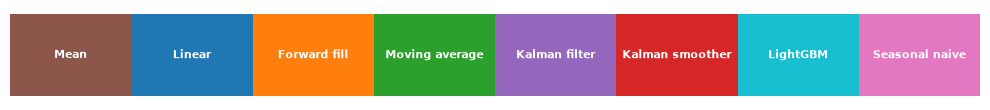

In [ ]:
KLEUREN = {
    "Mean": "#8c564b",
    "Linear": "#1f77b4",
    "Forward fill": "#ff7f0e",
    "Moving average": "#2ca02c",
    "Kalman filter": "#9467bd",
    "Kalman smoother": "#d62728",
    "LightGBM": "#17becf",
    "Seasonal naive": "#e377c2"}

KLEUR_BEKEND = "#ffd8f5"
KLEUR_ECHT = "black"

fig, ax = plt.subplots(figsize=(10, 1.2))
for i, (naam, kleur) in enumerate(KLEUREN.items()):
    ax.barh(0, 1, left=i, color=kleur)
    ax.text(i + 0.5, 0, naam, ha="center", va="center", color="white", fontsize=8, fontweight="bold")
ax.set_xlim(0, len(KLEUREN))
ax.axis("off")
plt.tight_layout()
plt.show()


1.5 Hulpfuncties voor de grafieken

> `toon_methode` laat per methode de 3 gaten naast elkaar zien: de bekende data rondom het gat in grijs en de schatting in de kleur van de methode
>
> `toon_gat` zet per gat alle methodes over elkaar, met of zonder de echte data

In [17]:
resultaten = {}

def context_posities(posities):
    marge = max(36, len(posities) // 2)
    return np.arange(max(0, posities[0] - marge), min(len(reeks), posities[-1] + marge + 1))


def schatting_met_randen(ingevuld, posities):
    rand = np.concatenate([[posities[0] - 1], posities, [posities[-1] + 1]])
    return ingevuld.iloc[rand]


def opmaak_as(ax, posities, titel):
    half = pd.Timedelta(minutes=2.5)
    ax.axvspan(reeks.index[posities[0]] - half, reeks.index[posities[-1]] + half, color="#e8e8e8", zorder=0)
    ax.set_title(titel, fontsize=10)
    ax.set_ylabel("POW (W)")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d-%m\n%H:%M"))
    ax.grid(alpha=0.3)


def toon_methode(naam):
    ingevuld = resultaten[naam]
    fig, assen = plt.subplots(1, 3, figsize=(15, 3.5))

    for ax, (gat_naam, posities) in zip(assen, gat_posities.items()):
        context = context_posities(posities)
        ax.plot(test_reeks.iloc[context], color=KLEUR_BEKEND, lw=1.2, label="bekende data")

        schatting = schatting_met_randen(ingevuld, posities)
        ax.plot(schatting, color=KLEUREN[naam], lw=1.8, marker="o" if len(posities) < 20 else None, ms=4, label=naam)
        opmaak_as(ax, posities, gat_naam)

    assen[0].legend(fontsize=8)
    fig.suptitle(naam, color=KLEUREN[naam], fontweight="bold")
    plt.tight_layout()
    plt.show()


def toon_gat(gat_naam, met_echt=False):
    posities = gat_posities[gat_naam]
    context = context_posities(posities)

    fig, ax = plt.subplots(figsize=(14, 4.5))
    ax.plot(test_reeks.iloc[context], color=KLEUR_BEKEND, lw=1.2, label="bekende data")

    for naam, ingevuld in resultaten.items():
        breedte = 2.4 if naam == ONZE_KEUZE[gat_naam] else 1.3
        ax.plot(schatting_met_randen(ingevuld, posities), color=KLEUREN[naam], lw=breedte,
                marker="o" if len(posities) < 20 else None, ms=4, label=naam)

    if met_echt:
        rand = np.concatenate([[posities[0] - 1], posities, [posities[-1] + 1]])
        ax.plot(echte_waarden.iloc[rand], color=KLEUR_ECHT, lw=2, ls="--",
                marker="x" if len(posities) < 20 else None, ms=7, label="echte data", zorder=10)

    opmaak_as(ax, posities, f"{gat_naam} (dikke lijn = onze keuze: {ONZE_KEUZE[gat_naam]})")
    ax.legend(fontsize=8, ncol=2, loc="upper left", bbox_to_anchor=(1.01, 1))
    plt.tight_layout()
    plt.show()

### 2. De methodes
___
> Elke methode krijgt `test_reeks` (met de 3 lege gaten) en geeft een reeks terug waarin de gaten zijn ingevuld. Na elke methode staat een grafiek met de schatting op de 3 gaten
>
> De echte waarden zie je hier nog **niet**. Zo beoordeel je eerst of de vorm logisch is, en pas in stap 3 hoe goed hij klopt

2.1 Mean

> Elk ontbrekend punt krijgt het gemiddelde van alle bekende metingen in de reeks. Dit is de simpelste methode en dient als ondergrens: elke andere methode moet hier duidelijk onder zitten met de fout
>
> Het dagpatroon gaat volledig verloren: 's nachts en overdag krijgen dezelfde waarde

> Bron: Moritz & Bartz-Beielstein (2017), [imputeTS: Time Series Missing Value Imputation in R](https://doi.org/10.32614/RJ-2017-009)

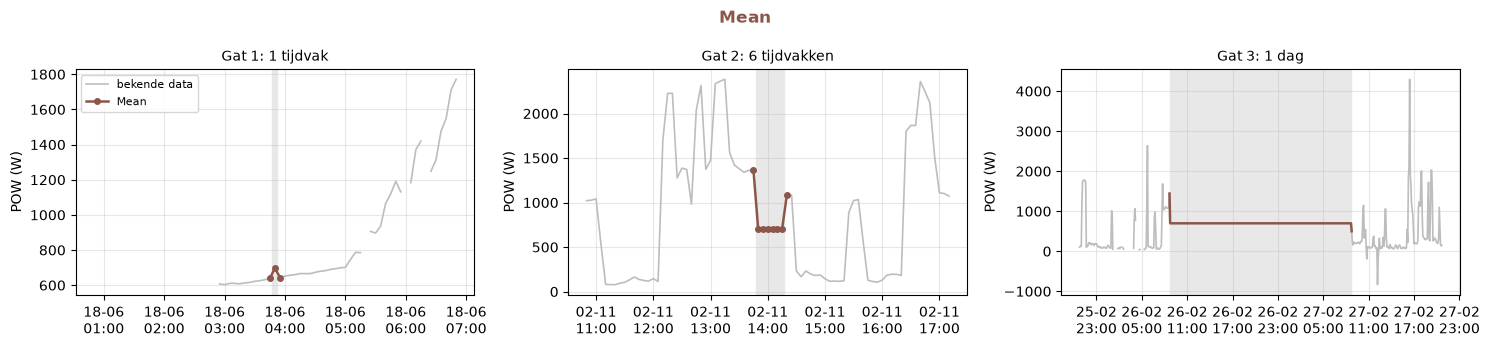

In [18]:
def vul_mean(reeks_met_gaten):
    return reeks_met_gaten.fillna(reeks_met_gaten.mean())


resultaten["Mean"] = vul_mean(test_reeks)
toon_methode("Mean")

2.2 Linear

> Een rechte lijn tussen de laatste meting vóór en de eerste meting ná het gat. Dit is wat we in 06_Dataprep gebruiken voor gaten van 5 tot 15 minuten
>
> Bij een kort gat verandert het verbruik weinig en is een rechte lijn een goede schatting. Bij een lang gat mist hij alles wat er tussendoor gebeurt, zoals het dagpatroon

> Bron: Moritz & Bartz-Beielstein (2017), [imputeTS: Time Series Missing Value Imputation in R](https://doi.org/10.32614/RJ-2017-009)

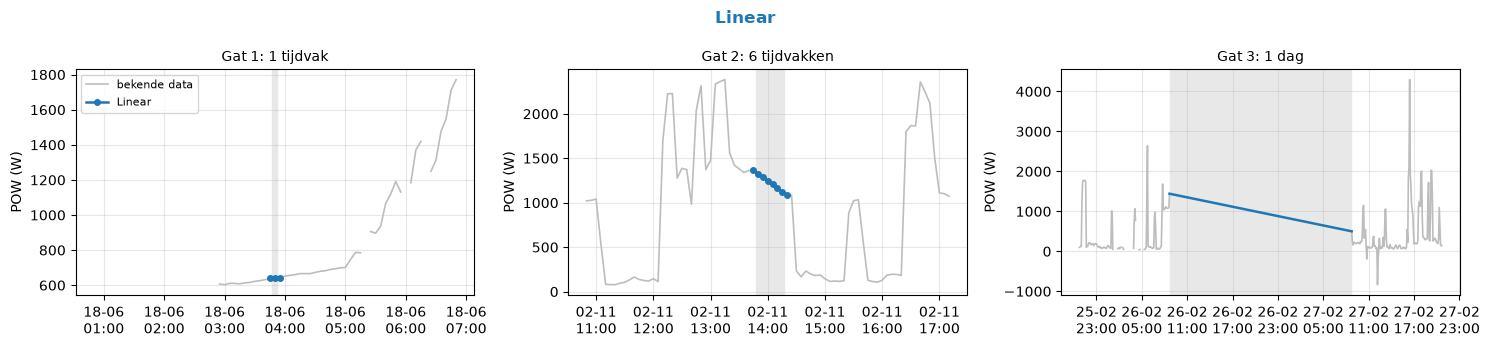

In [19]:
def vul_linear(reeks_met_gaten):
    return reeks_met_gaten.interpolate(method="time", limit_area="inside")


resultaten["Linear"] = vul_linear(test_reeks)
toon_methode("Linear")

2.3 Forward fill

> De laatste meting vóór het gat wordt herhaald tot het gat voorbij is (in imputeTS heet dit LOCF: *last observation carried forward*)
>
> Hiermee gebruiken we alleen data uit het verleden, net als bij een live meter die even geen data stuurt. Bij lange gaten blijft de waarde de hele tijd plat

> Bron: Moritz & Bartz-Beielstein (2017), [imputeTS: Time Series Missing Value Imputation in R](https://doi.org/10.32614/RJ-2017-009)

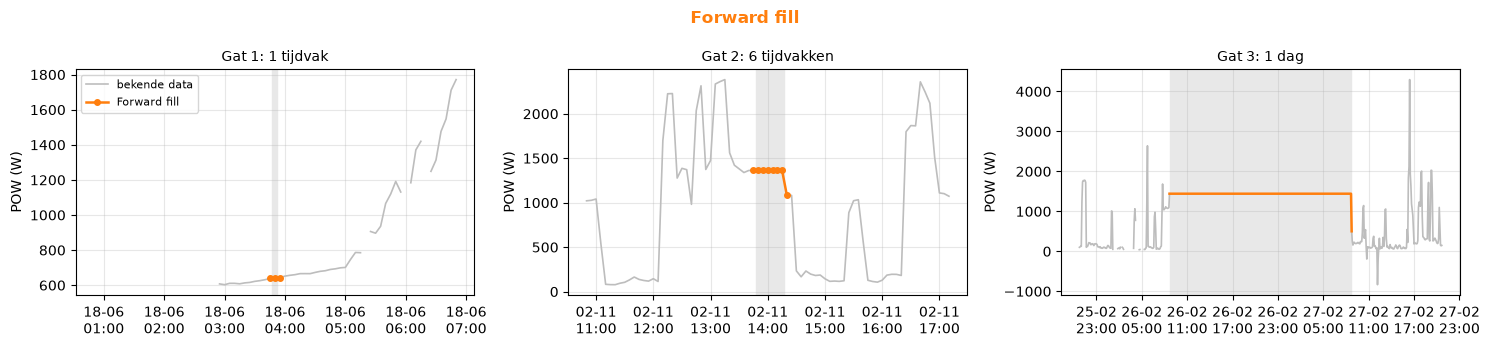

In [20]:
def vul_forward_fill(reeks_met_gaten):
    return reeks_met_gaten.ffill()


resultaten["Forward fill"] = vul_forward_fill(test_reeks)
toon_methode("Forward fill")

2.4 Moving average

> Elk ontbrekend punt krijgt het gemiddelde van de bekende metingen in een venster eromheen: 6 tijdvakken (30 minuten) aan beide kanten
>
> Staan er in dat venster minder dan 2 bekende metingen, dan wordt het venster steeds 1 tijdvak breder tot dat wel zo is. Zo werkt `na_ma` in imputeTS ook. In het midden van een lang gat wordt het venster daardoor heel breed en lijkt de uitkomst op een gemiddelde van de randen

> Bron: Moritz & Bartz-Beielstein (2017), [imputeTS: Time Series Missing Value Imputation in R](https://doi.org/10.32614/RJ-2017-009)

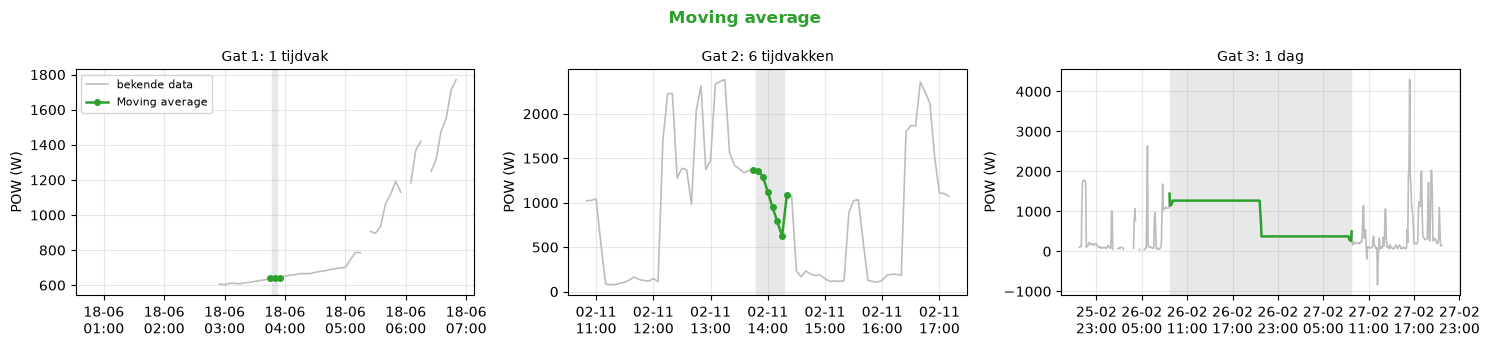

In [21]:
def vul_moving_average(reeks_met_gaten, k=6):
    waarden = reeks_met_gaten.to_numpy(dtype=float)
    ingevuld = waarden.copy()

    for i in np.flatnonzero(np.isnan(waarden)):
        breedte = k

        while True:
            buren = waarden[max(0, i - breedte):i + breedte + 1]
            buren = buren[~np.isnan(buren)]
            if len(buren) >= 2 or breedte > len(waarden):
                break
            breedte += 1

        ingevuld[i] = buren.mean()

    return pd.Series(ingevuld, index=reeks_met_gaten.index)


def vul_moving_average_test(reeks_met_gaten, gaten):
    resultaat = reeks_met_gaten.copy()

    for posities in gaten.values():
        van = max(0, posities[0] - PUNTEN_PER_DAG)
        tot = min(len(reeks_met_gaten), posities[-1] + PUNTEN_PER_DAG + 1)
        stuk = vul_moving_average(reeks_met_gaten.iloc[van:tot])
        resultaat.iloc[posities] = stuk.iloc[posities - van].to_numpy()

    return resultaat


resultaten["Moving average"] = vul_moving_average_test(test_reeks, gat_posities)
toon_methode("Moving average")

2.5 Kalman: model per gat schatten

> Kalman filter en Kalman smoother gebruiken **hetzelfde model** als in 06_Dataprep: een niveau dat langzaam mag veranderen plus een dagpatroon van 24 uur (3 golven). Het verschil zit alleen in welke data ze mogen gebruiken
>
> Per gat wordt het model geschat op een venster van 7 dagen vóór tot 7 dagen ná het gat (met het gat leeg). Zo krijgen filter en smoother precies dezelfde instellingen en is de vergelijking eerlijk. In 06_Dataprep schatten we de instellingen op de 30 beste dagen, omdat het daar om de hele reeks gaat

> Bron: Durbin & Koopman (2001), *Time Series Analysis by State Space Methods*, Oxford University Press
>
> Bron: Harvey (1989), [Forecasting, Structural Time Series Models and the Kalman Filter](https://doi.org/10.1017/CBO9781107049994), Cambridge University Press

In [22]:
def maak_kalman_model(stuk):
    return UnobservedComponents(stuk,
                                level="local level",
                                freq_seasonal=[{"period": PUNTEN_PER_DAG, "harmonics": 3}])


def schat_kalman(reeks_met_gaten, gaten):
    kalman = {}

    for naam, posities in gaten.items():
        van = max(0, posities[0] - 7 * PUNTEN_PER_DAG)
        tot = min(len(reeks_met_gaten), posities[-1] + 7 * PUNTEN_PER_DAG + 1)
        stuk = reeks_met_gaten.iloc[van:tot].to_numpy(dtype=float)

        model = maak_kalman_model(stuk)
        params = model.fit(disp=False).params

        #smooth() berekent zowel de filter- als de smoother-uitkomst
        kalman[naam] = {"posities": posities, "van": van, "uitkomst": model.smooth(params)}

    return kalman


kalman_per_gat = schat_kalman(test_reeks, gat_posities)

print("Kalman model geschat voor", len(kalman_per_gat), "gaten")

Kalman model geschat voor 3 gaten


2.6 Kalman filter

> Het filter loopt van links naar rechts door de reeks en gebruikt bij elk punt **alleen de data van vóór dat punt**. In het gat voorspelt het dus vooruit met het niveau en dagpatroon dat het tot dan toe geleerd heeft
>
> Dit is de situatie van een live systeem: je weet nog niet wat er na het gat komt. Daardoor sluit de schatting aan het eind van het gat vaak niet aan op de volgende meting

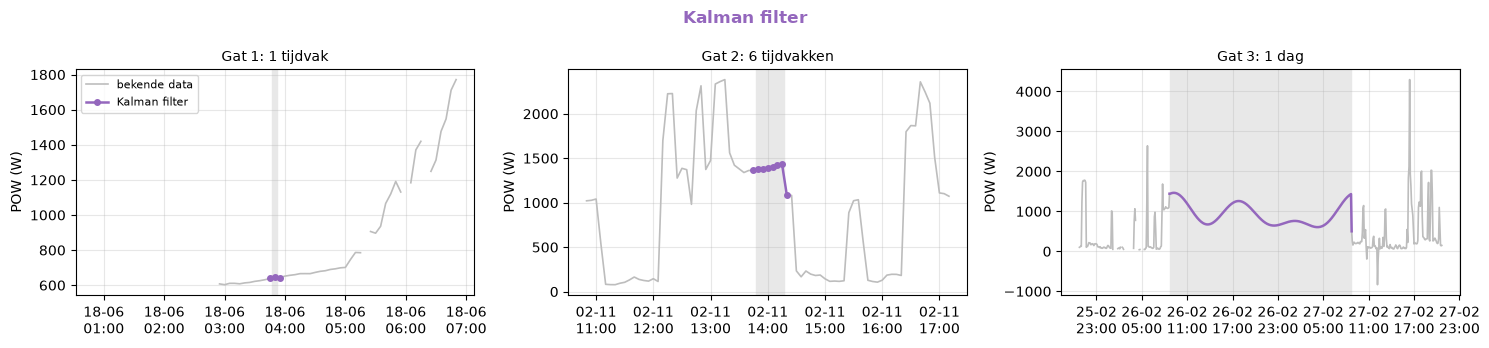

In [23]:
def vul_kalman(reeks_met_gaten, kalman, soort):
    resultaat = reeks_met_gaten.copy()

    for gat in kalman.values():
        posities, van, uitkomst = gat["posities"], gat["van"], gat["uitkomst"]

        signaal = uitkomst.level[soort] + uitkomst.freq_seasonal[0][soort]
        resultaat.iloc[posities] = signaal[posities - van]

    return resultaat


resultaten["Kalman filter"] = vul_kalman(test_reeks, kalman_per_gat, "filtered")
toon_methode("Kalman filter")

2.7 Kalman smoother

> De smoother gaat na het filter ook nog terug van rechts naar links. Elk punt gebruikt zo de data van **vóór én ná** het gat. Dit is wat we in 06_Dataprep gebruiken voor gaten van 20 tot 60 minuten
>
> Bij het invullen van oude data is de data na het gat altijd bekend, dus hoort de smoother beter te scoren dan het filter. Stap 3 laat zien of dat klopt

> Bron: Moritz & Bartz-Beielstein (2017), [imputeTS: Time Series Missing Value Imputation in R](https://doi.org/10.32614/RJ-2017-009)

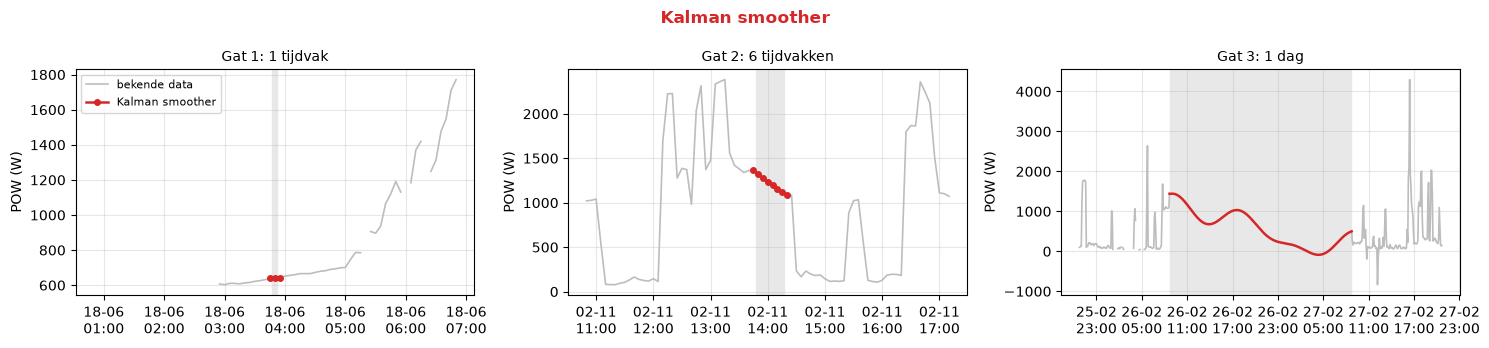

In [24]:
resultaten["Kalman smoother"] = vul_kalman(test_reeks, kalman_per_gat, "smoothed")
toon_methode("Kalman smoother")

2.8 LightGBM

> Zelfde aanpak als 06_Dataprep: het model leert uit **hoe laat het is, welke dag het is en wat er op dezelfde tijd op eerdere dagen gemeten is**. Dit gebruiken we voor gaten van 65 minuten tot 1 dag
>
> Het model wordt getraind op `test_reeks`, dus de 3 test-gaten zitten **niet** in de trainingsdata. Anders zou het model de antwoorden al kennen
>
> Instellingen zoals in 06_Dataprep: leersnelheid 0,05, 31 bladeren, minimaal 50 punten per blad, 80% van de data per boom, en early stopping op de laatste 20% (in tijd)

> Bron: Kaur & Gabrijelčič (2027), [Performance of missing data imputation methods for electricity consumption time series data: a comparative study](https://doi.org/10.1016/j.epsr.2026.113963)
>
> Bron: Hörbe & Erol (2025), [Optimizing LightGBM for Regression: A Study on Parameter Influence and Performance](https://doi.org/10.1016/j.ifacol.2025.09.385)

c:\Users\Matti\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Aantal bomen na early stopping: 48


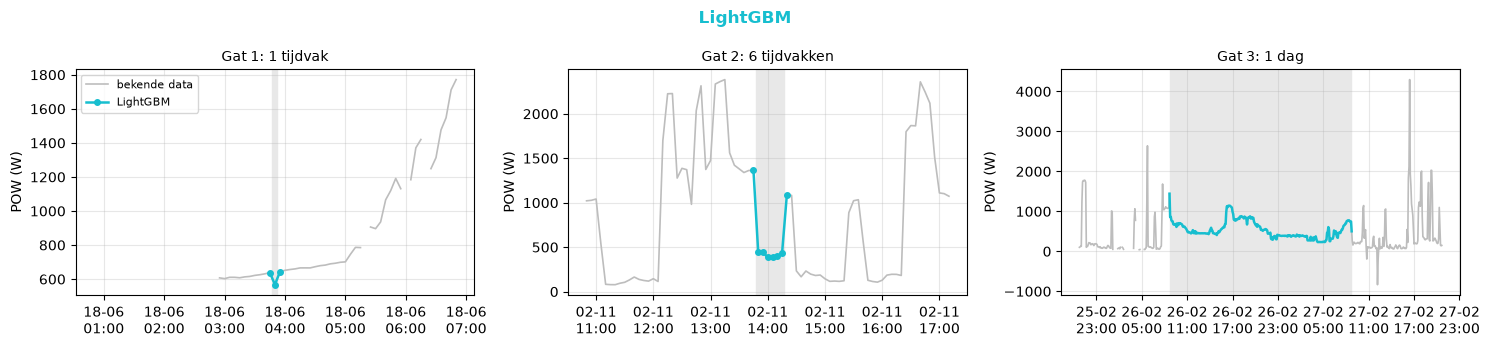

In [25]:
def maak_lightgbm_features(reeks_met_gaten):
    tijd = reeks_met_gaten.index
    minuut_van_dag = tijd.hour * 60 + tijd.minute
    dag_van_jaar = tijd.dayofyear

    eerdere_dagen = pd.concat([reeks_met_gaten.shift(d * PUNTEN_PER_DAG) for d in range(1, 8)], axis=1)

    return pd.DataFrame({
        "dag_sin": np.sin(2 * np.pi * minuut_van_dag / 1440),
        "dag_cos": np.cos(2 * np.pi * minuut_van_dag / 1440),
        "uur": tijd.hour,

        "weekdag": tijd.dayofweek,
        "weekend": (tijd.dayofweek >= 5).astype(int),

        "jaar_sin": np.sin(2 * np.pi * dag_van_jaar / 365.25),
        "jaar_cos": np.cos(2 * np.pi * dag_van_jaar / 365.25),

        "zelfde_tijd_gisteren": eerdere_dagen.iloc[:, 0],
        "zelfde_tijd_vorige_week": eerdere_dagen.iloc[:, 6],
        "gem_zelfde_tijd_7_dagen": eerdere_dagen.mean(axis=1)}, index=reeks_met_gaten.index)


def vul_lightgbm(reeks_met_gaten, posities, toon=True):
    X = maak_lightgbm_features(reeks_met_gaten)
    y = reeks_met_gaten

    echt = y.notna().to_numpy()
    grens = np.flatnonzero(echt)[int(echt.sum() * 0.8)]
    positie = np.arange(len(y))
    train = echt & (positie < grens)
    controle = echt & (positie >= grens)

    model = lgb.LGBMRegressor(n_estimators=1000,
                              learning_rate=0.05,
                              num_leaves=31,
                              min_child_samples=50,
                              subsample=0.8,
                              subsample_freq=1,
                              verbose=-1)

    model.fit(X[train], y[train],
              eval_set=[(X[controle], y[controle])],
              eval_metric="l1",
              callbacks=[lgb.early_stopping(50, verbose=False)])

    resultaat = reeks_met_gaten.copy()
    resultaat.iloc[posities] = model.predict(X.iloc[posities])

    if toon:
        print("Aantal bomen na early stopping:", model.best_iteration_)
    return resultaat


resultaten["LightGBM"] = vul_lightgbm(test_reeks, alle_posities)
toon_methode("LightGBM")

2.9 Seasonal naive (eigen toevoeging)

> Elk ontbrekend punt krijgt de waarde van **precies 24 uur eerder**. Ontbreekt die ook, dan 2 dagen eerder, enzovoort tot maximaal een week terug
>
> Waarom deze erbij? Het is de simpelste methode die wél het dagpatroon meeneemt. Daarmee is het de eerlijke lat voor LightGBM: als LightGBM met al zijn kenmerken niet beter is dan "gewoon gisteren kopiëren", dan voegt het model niets toe. In 06_Dataprep (4.7) vergelijken we LightGBM daarom ook al met deze waarde
>
> Bij korte gaten verwachten we dat hij slecht scoort: gisteren om 14:05 zegt minder over vandaag 14:05 dan de meting van 5 minuten eerder

> Bron: Hyndman & Athanasopoulos (2021), [Forecasting: Principles and Practice, 3e editie, hoofdstuk 5.2 Some simple forecasting methods](https://otexts.com/fpp3/simple-methods.html)

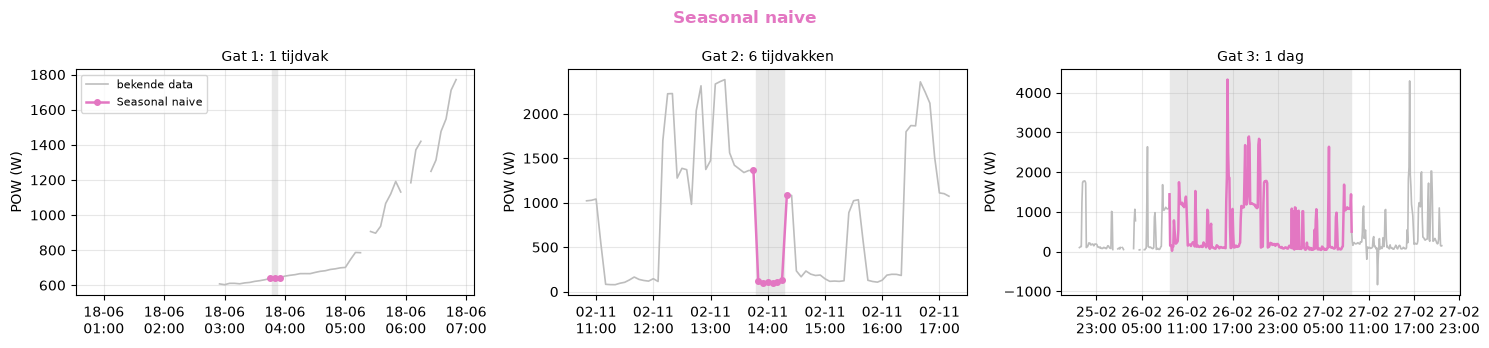

In [26]:
def vul_seasonal_naive(reeks_met_gaten):
    resultaat = reeks_met_gaten.copy()

    for dagen in range(1, 8):
        resultaat = resultaat.fillna(reeks_met_gaten.shift(dagen * PUNTEN_PER_DAG))

    return resultaat


resultaten["Seasonal naive"] = vul_seasonal_naive(test_reeks)
toon_methode("Seasonal naive")

### 3. Vergelijken
___
> Eerst alle methodes per gat over elkaar, nog zonder de echte data. Daarna komt de echte data eroverheen en rekenen we de fouten uit

3.1 Alle methodes per gat, zonder echte data

> De dikke lijn is de methode die we in 06_Dataprep voor deze gatlengte gekozen hebben

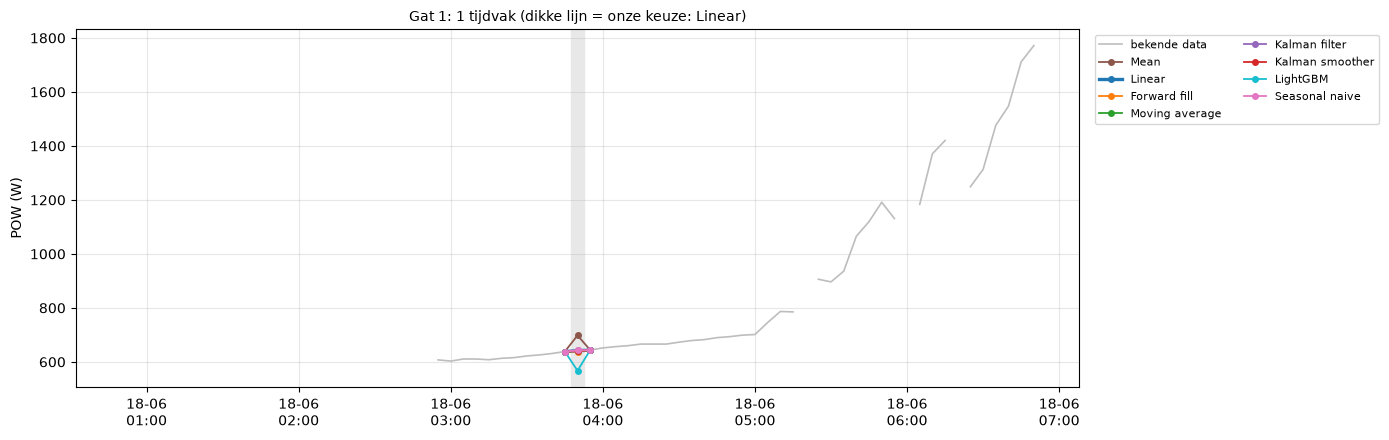

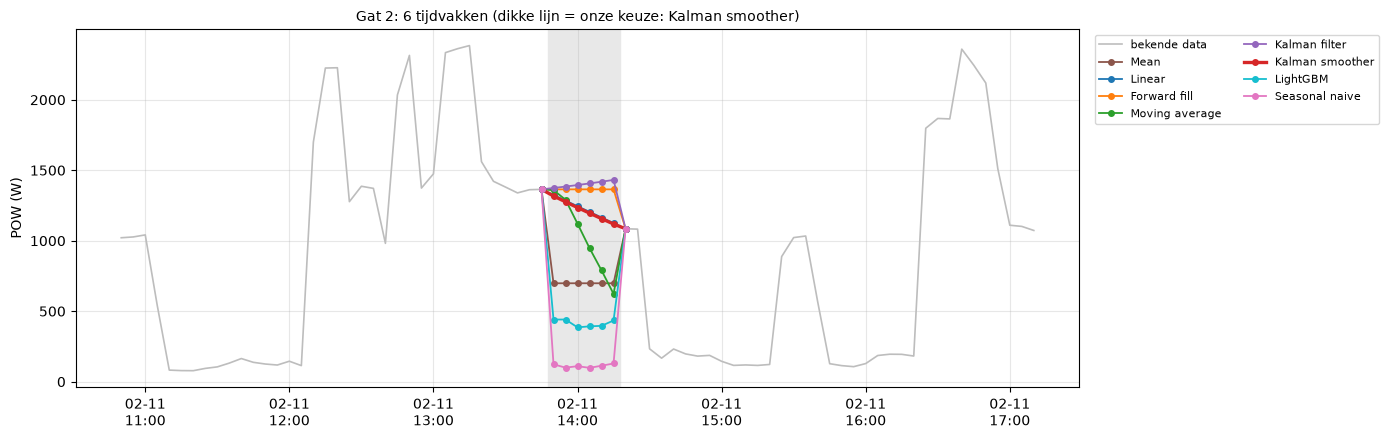

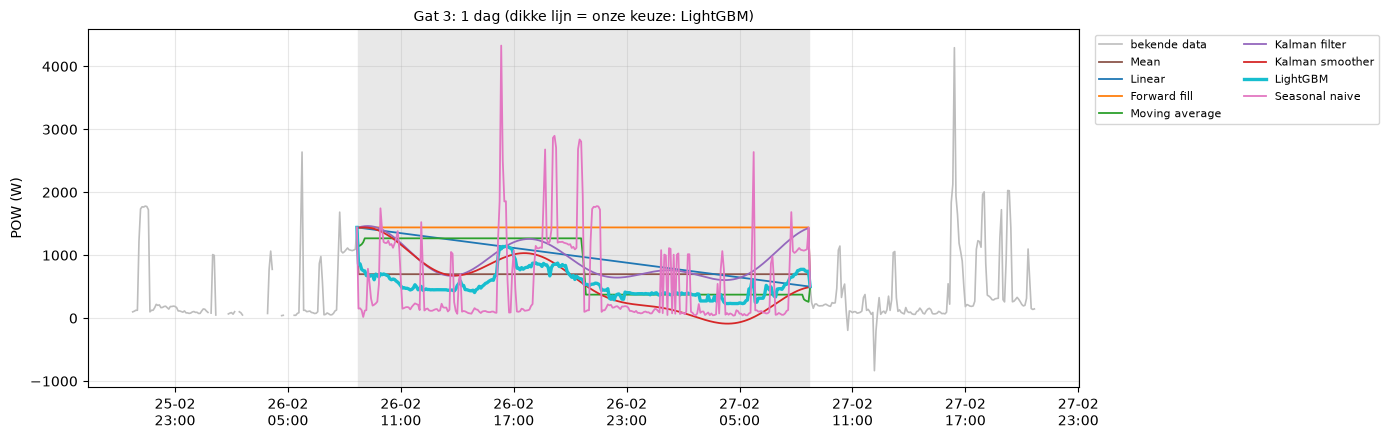

In [27]:
for gat_naam in gat_posities:
    toon_gat(gat_naam, met_echt=False)

3.2 Echte data eroverheen

> Dezelfde grafieken, nu met de echte metingen zwart gestippeld. Hoe dichter een gekleurde lijn bij de zwarte lijn ligt, hoe beter de methode

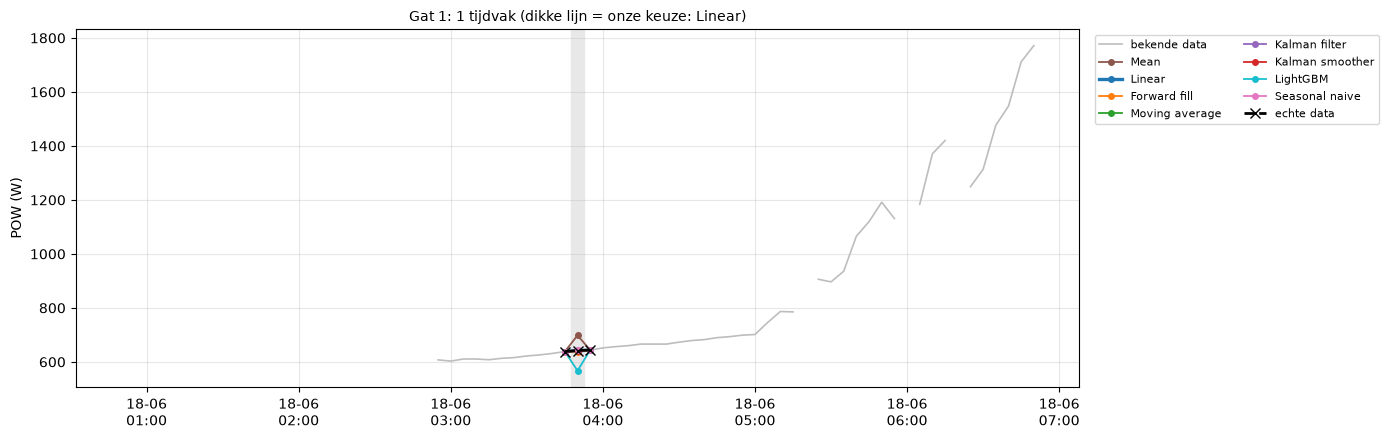

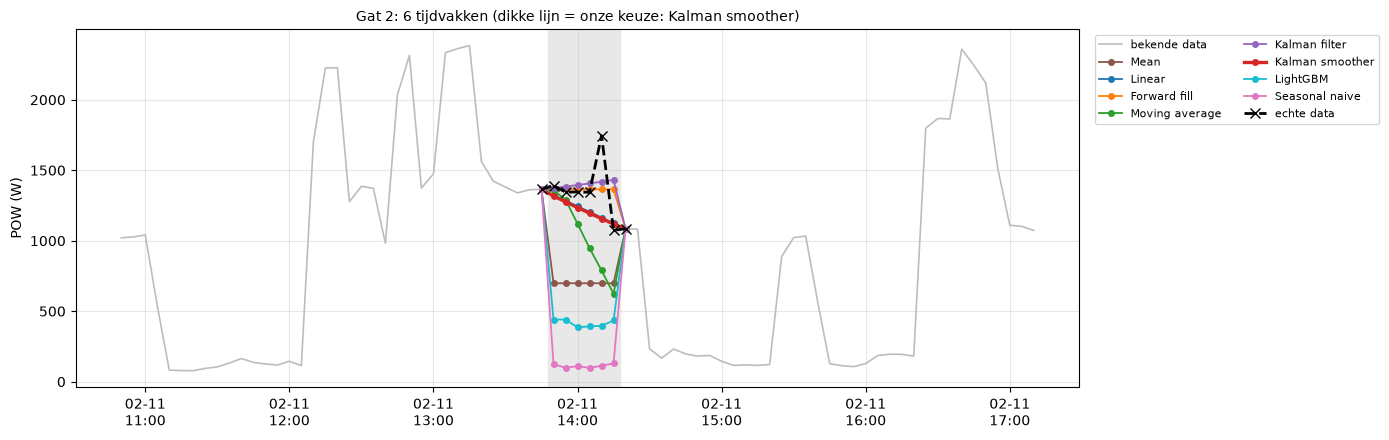

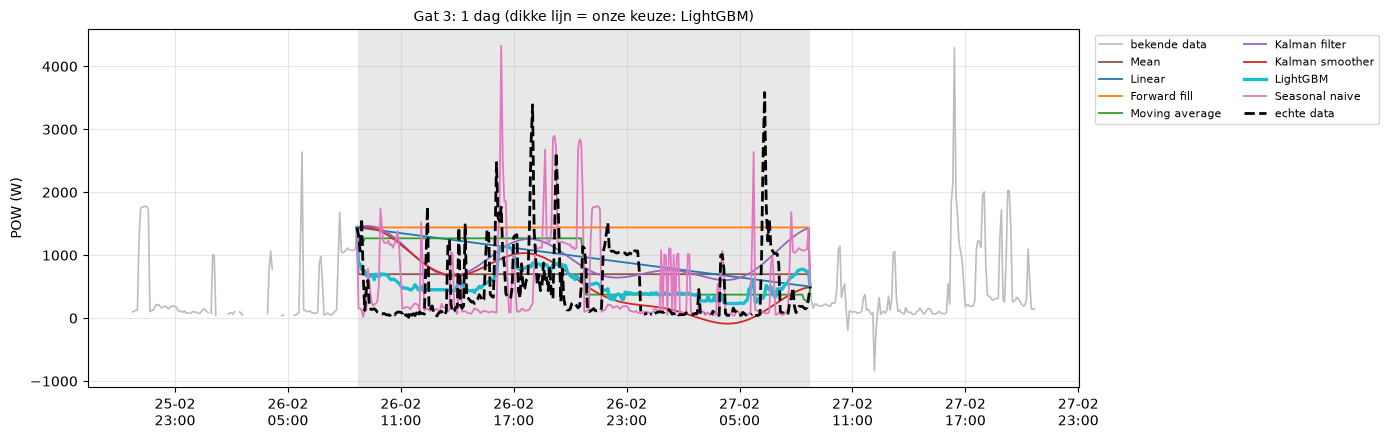

In [28]:
for gat_naam in gat_posities:
    toon_gat(gat_naam, met_echt=True)

3.3 Fouten per methode per gat

> **MAE** (gemiddelde absolute fout): hoeveel watt de schatting gemiddeld naast de echte waarde zit
>
> **RMSE** (wortel van de gemiddelde gekwadrateerde fout): ook in watt, maar grote missers tellen zwaarder mee. Is de RMSE veel groter dan de MAE, dan zitten er een paar flinke uitschieters in
>
> Lager is bij beide beter. MAPE (fout in procenten) uit het ML Canvas laten we hier bewust weg: bij waarden rond 0 W (bijvoorbeeld opwekking 's nachts) deel je door bijna nul en wordt het percentage onbruikbaar groot
>
> Punten in het dag-gat die al ontbraken in de data tellen niet mee, daar is geen echte waarde om mee te vergelijken
>
> Let op bij gat 1: dat is maar **1 punt**, dus MAE en RMSE zijn daar gelijk en de uitslag hangt van één meting af

In [29]:
regels = []

for gat_naam, posities in gat_posities.items():
    echt = echte_waarden.iloc[posities].to_numpy()
    gemeten = ~np.isnan(echt)

    for naam, ingevuld in resultaten.items():
        fout = ingevuld.iloc[posities].to_numpy()[gemeten] - echt[gemeten]
        regels.append({"gat": gat_naam,
                       "methode": naam,
                       "MAE": np.abs(fout).mean(),
                       "RMSE": np.sqrt((fout ** 2).mean())})

fouten = pd.DataFrame(regels)

leeg = fouten[fouten["MAE"].isna()]
if len(leeg) > 0:
    print("Let op, niet volledig ingevuld:", leeg[["gat", "methode"]].values.tolist())

fouten["plek"] = fouten.groupby("gat")["MAE"].rank(method="min").astype("Int64")

fouten.pivot(index="methode", columns="gat", values=["MAE", "RMSE"]).round(1).loc[list(KLEUREN)]

MAE                                   \
gat             Gat 1: 1 tijdvak Gat 2: 6 tijdvakken Gat 3: 1 dag   
methode                                                             
Mean                        56.1               676.0        550.9   
Linear                       1.1               166.5        707.6   
Forward fill                 3.9               126.2       1046.4   
Moving average               1.3               352.5        660.7   
Kalman filter                1.8               142.1        688.8   
Kalman smoother              2.3               172.5        538.8   
LightGBM                    74.7               959.2        463.7   
Seasonal naive               0.0              1262.0        616.3   

                            RMSE                                   
gat             Gat 1: 1 tijdvak Gat 2: 6 tijdvakken Gat 3: 1 dag  
methode                                                            
Mean                        56.1               703.9        633.3  
Linear                       1.1               250.8        820.1  
Forward fill                 3.9               196.4       1134.6  
Moving average               1.3               470.7        794.3  
Kalman filter                1.8               201.1        775.7  
Kalman smoother              2.3               256.0        709.4  
LightGBM                    74.7               981.3        579.3  
Seasonal naive               0.0              1277.7        885.7

3.4 Fouten als grafiek

> Per gat de MAE van elke methode, in de vaste kleur. De balk met de zwarte rand is onze keuze uit 06_Dataprep

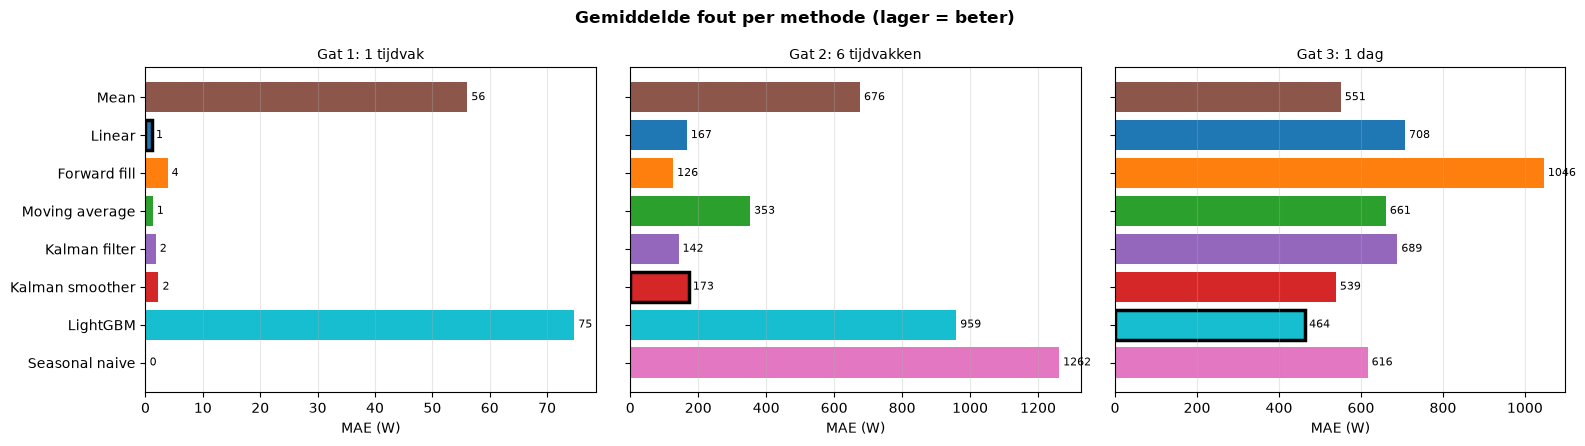

In [30]:
fig, assen = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, gat_naam in zip(assen, gat_posities):
    deel = fouten[fouten["gat"] == gat_naam].set_index("methode").loc[list(KLEUREN)]

    balken = ax.barh(deel.index, deel["MAE"], color=[KLEUREN[n] for n in deel.index])

    i = list(deel.index).index(ONZE_KEUZE[gat_naam])
    balken[i].set_edgecolor("black")
    balken[i].set_linewidth(2.5)

    for balk, waarde in zip(balken, deel["MAE"]):
        ax.text(balk.get_width(), balk.get_y() + balk.get_height() / 2, f" {waarde:.0f}", va="center", fontsize=8)

    ax.invert_yaxis()
    ax.set_title(gat_naam, fontsize=10)
    ax.set_xlabel("MAE (W)")
    ax.grid(axis="x", alpha=0.3)

assen[1].set_yticklabels([])
assen[2].set_yticklabels([])
fig.suptitle("Gemiddelde fout per methode (lager = beter)", fontweight="bold")
plt.tight_layout()
plt.show()

3.5 Hoe scoort onze keuze?

> Per gat: de beste methode, onze keuze uit 06_Dataprep en de plek van onze keuze tussen de 8 methodes

In [31]:
samenvatting = []

for gat_naam in gat_posities:
    deel = fouten[fouten["gat"] == gat_naam].set_index("methode")
    beste = deel["MAE"].idxmin()
    keuze = ONZE_KEUZE[gat_naam]

    samenvatting.append({"gat": gat_naam,
                         "beste methode": beste,
                         "MAE beste": round(deel.loc[beste, "MAE"], 1),
                         "onze keuze": keuze,
                         "MAE onze keuze": round(deel.loc[keuze, "MAE"], 1),
                         "plek onze keuze": f"{deel.loc[keuze, 'plek']} van {len(deel)}"})

pd.DataFrame(samenvatting).set_index("gat")

,beste methode,MAE beste,onze keuze,MAE onze keuze,plek onze keuze
gat,,,,,
Gat 1: 1 tijdvak,Seasonal naive,0.0,Linear,1.1,2 van 8
Gat 2: 6 tijdvakken,Forward fill,126.2,Kalman smoother,172.5,4 van 8
Gat 3: 1 dag,LightGBM,463.7,LightGBM,463.7,1 van 8


3.6 Conclusie

> *Invullen na het runnen met de echte gaten.* Punten om op te letten:
>
> - Staat onze keuze per gat op of dicht bij plek 1? Zo niet, welke methode wint en is het verschil groot of klein (in watt)?
> - Gat 2: scoort de Kalman smoother beter dan het Kalman filter? Dat onderbouwt de keuze voor de smoother
> - Gat 3: scoort LightGBM beter dan Seasonal naive? Zo niet, dan voegt het model weinig toe
> - Dit is een test op 3 willekeurig gekozen gaten. Eén gat per lengte kan toevallig gunstig of ongunstig uitvallen, zeker gat 1 (één punt). Stap 4 herhaalt de test daarom op veel meer gaten

### 4. Test in rondes op veel gaten
___
> Eén gat per lengte kan toevallig gunstig of ongunstig uitvallen. Daarom knippen we zelf extra gaten uit de data, op plekken waar alles echt gemeten is, en herhalen we de test
>
> Dat gebeurt in **rondes**. Per ronde worden per lengte een paar gaten tegelijk leeggemaakt, alle 8 methodes vullen ze in, en daarna begint de volgende ronde weer met de volledige data
>
> Waarom rondes en niet alle gaten in één keer? Als je heel veel gaten tegelijk weghaalt, verandert de data zelf: LightGBM heeft minder om van te leren en "zelfde tijd gisteren" valt vaker in een ander gat. Met rondes blijft elke test dicht bij de echte situatie. Het laat ook zien of de winnaar per ronde hetzelfde blijft

4.1 Instellingen

> Standaard 10 rondes met per ronde 5 gaten per lengte, dus 50 gaten per lengte in totaal
>
> Dezelfde regels als in 1.2: na de eerste week, buren echt gemeten en minstens 95% van het gat, en binnen een ronde minstens **8 dagen** tussen de gaten
>
> Gaten van dezelfde lengte overlappen nooit met een gat uit een eerdere ronde, zodat er geen bijna-dubbele tests in zitten. Ook hier zorgt `STARTGETAL` uit 1.2 ervoor dat iedereen in de groep dezelfde gaten krijgt. De rondes gebruiken wel een eigen reeks willekeurige getallen, zodat ze niet dezelfde gaten trekken als 1.2
>
> **Rekentijd:** per ronde wordt LightGBM één keer getraind en het Kalman model 15 keer geschat. Reken op enkele minuten per ronde. Zet `RONDES` eerst op 1 om te testen

In [32]:
RONDES = 10
GATEN_PER_LENGTE = 5

LENGTES = {"1 tijdvak": 1, "6 tijdvakken": 6, "1 dag": PUNTEN_PER_DAG}

ONZE_KEUZE_LENGTE = {"1 tijdvak": "Linear", "6 tijdvakken": "Kalman smoother", "1 dag": "LightGBM"}

rng = np.random.default_rng(STARTGETAL + 1)

4.2 Mogelijke plekken zoeken

> Met `mogelijke_starts` uit 1.2. Per lengte zie je hoeveel startpunten er zijn en hoeveel gaten er over alle rondes nodig zijn
>
> Startpunten mogen elkaar overlappen, het echte aantal losse gaten is dus kleiner

In [33]:
starts = {naam: mogelijke_starts(lengte) for naam, lengte in LENGTES.items()}

pd.DataFrame({"mogelijke startpunten": {naam: len(s) for naam, s in starts.items()},
              "nodig over alle rondes": {naam: RONDES * GATEN_PER_LENGTE for naam in LENGTES}})

,mogelijke startpunten,nodig over alle rondes
1 tijdvak,178284,50
6 tijdvakken,155176,50
1 dag,43492,50


4.3 Gaten kiezen per ronde

> Per ronde worden eerst de dag-gaten gekozen (daar zijn de minste plekken voor), daarna 6 tijdvakken en daarna 1 tijdvak. Een plek wordt alleen gekozen als hij minstens 8 dagen afstand houdt tot de andere gaten in dezelfde ronde
>
> Lukt het niet om genoeg gaten te vinden, dan gaat de ronde door met minder gaten en krijg je een melding

In [34]:
def kies_ronde(gebruikt):
    gaten = {}
    bezet = []

    for naam in sorted(LENGTES, key=LENGTES.get, reverse=True):
        lengte = LENGTES[naam]
        aantal = 0

        for start in rng.permutation(starts[naam]):
            if aantal == GATEN_PER_LENGTE:
                break
            eind = start + lengte - 1

            if gebruikt[naam][start:eind + 1].any():
                continue

            if te_dichtbij(start, eind, bezet):
                continue

            aantal += 1
            gebruikt[naam][start:eind + 1] = True
            bezet.append((start, eind))
            gaten[(naam, aantal)] = np.arange(start, eind + 1)

        if aantal < GATEN_PER_LENGTE:
            print(f"Let op: maar {aantal} van de {GATEN_PER_LENGTE} gaten van '{naam}' gevonden in deze ronde")

    return gaten

4.4 Alle methodes in één functie

> Dezelfde functies als in stap 2, alleen nu voor een willekeurige set gaten

In [35]:
def vul_alle_methodes(reeks_met_gaten, gaten):
    alle = np.concatenate(list(gaten.values()))
    kalman = schat_kalman(reeks_met_gaten, gaten)

    return {
        "Mean": vul_mean(reeks_met_gaten),
        "Linear": vul_linear(reeks_met_gaten),
        "Forward fill": vul_forward_fill(reeks_met_gaten),
        "Moving average": vul_moving_average_test(reeks_met_gaten, gaten),
        "Kalman filter": vul_kalman(reeks_met_gaten, kalman, "filtered"),
        "Kalman smoother": vul_kalman(reeks_met_gaten, kalman, "smoothed"),
        "LightGBM": vul_lightgbm(reeks_met_gaten, alle, toon=False),
        "Seasonal naive": vul_seasonal_naive(reeks_met_gaten)}

4.5 Rondes draaien

> Per ronde: gaten kiezen, leegmaken in een kopie van de volledige reeks, alle methodes laten invullen en per gat de fout (MAE en RMSE) opslaan

In [36]:
regels = []
gebruikt = {naam: np.zeros(len(reeks), dtype=bool) for naam in LENGTES}

for ronde in range(1, RONDES + 1):
    gaten = kies_ronde(gebruikt)

    ronde_reeks = reeks.copy()
    ronde_reeks.iloc[np.concatenate(list(gaten.values()))] = np.nan

    uitkomst = vul_alle_methodes(ronde_reeks, gaten)

    for (lengte, nummer), posities in gaten.items():
        echt = reeks.iloc[posities].to_numpy()
        gemeten = ~np.isnan(echt)

        for methode, ingevuld in uitkomst.items():
            fout = ingevuld.iloc[posities].to_numpy()[gemeten] - echt[gemeten]
            regels.append({"ronde": ronde,
                           "lengte": lengte,
                           "gat": f"r{ronde}-{nummer}",
                           "start": reeks.index[posities[0]],
                           "methode": methode,
                           "MAE": np.abs(fout).mean(),
                           "RMSE": np.sqrt((fout ** 2).mean())})

    print(f"Ronde {ronde} van {RONDES} klaar ({len(gaten)} gaten)")

rondes = pd.DataFrame(regels)

rondes["plek"] = rondes.groupby(["lengte", "gat"])["MAE"].rank(method="min")

leeg = rondes[rondes["MAE"].isna()]
if len(leeg) > 0:
    print("Let op, niet volledig ingevuld:", leeg.groupby("methode").size().to_dict())

c:\Users\Matti\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Ronde 1 van 10 klaar (15 gaten)


c:\Users\Matti\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Ronde 2 van 10 klaar (15 gaten)


c:\Users\Matti\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Ronde 3 van 10 klaar (15 gaten)


... (10 outputs left out)

c:\Users\Matti\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Ronde 9 van 10 klaar (15 gaten)


c:\Users\Matti\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Ronde 10 van 10 klaar (15 gaten)
Let op, niet volledig ingevuld: {'Seasonal naive': 1}


4.6 Gemiddelde fout per methode

> Gemiddelde MAE over alle gaten van dezelfde lengte, met tussen haakjes de spreiding (standaardafwijking). Een kleine spreiding betekent dat de methode stabiel is: niet de ene keer heel goed en de andere keer heel slecht

In [37]:
volgorde = list(LENGTES)

gemiddeld = rondes.groupby(["methode", "lengte"])["MAE"].agg(["mean", "std"])
tabel = (gemiddeld["mean"].round(1).astype(str) + " (" + gemiddeld["std"].round(1).astype(str) + ")").unstack()

tabel.loc[list(KLEUREN), volgorde]

lengte,1 tijdvak,6 tijdvakken,1 dag
methode,,,
Mean,683.3 (727.0),585.4 (384.0),564.2 (57.8)
Linear,199.3 (325.8),286.7 (297.8),582.9 (256.4)
Forward fill,208.7 (299.9),325.7 (350.3),607.0 (355.6)
Moving average,356.1 (580.6),322.9 (255.6),605.9 (262.3)
Kalman filter,262.4 (345.6),304.0 (304.0),628.3 (336.5)
Kalman smoother,236.2 (353.2),283.5 (289.9),573.7 (239.1)
LightGBM,678.6 (749.4),538.4 (412.1),462.1 (68.0)
Seasonal naive,915.9 (921.2),501.2 (371.6),543.8 (98.3)


4.7 Hoe vaak is elke methode de beste?

> Per lengte: bij hoeveel procent van de gaten had deze methode de laagste fout van alle 8, en wat de gemiddelde plek was (1 = beste, 8 = slechtste)

In [38]:
aantal_gaten = rondes.groupby("lengte")["gat"].nunique()

beste_pct = (rondes[rondes["plek"] == 1].groupby(["methode", "lengte"]).size()
             .unstack(fill_value=0).reindex(index=list(KLEUREN), columns=volgorde, fill_value=0)
             .div(aantal_gaten[volgorde]) * 100).round(0)

gem_plek = rondes.groupby(["methode", "lengte"])["plek"].mean().unstack().loc[list(KLEUREN), volgorde].round(1)

pd.concat({"% van de gaten beste": beste_pct, "gemiddelde plek": gem_plek}, axis=1)

% van de gaten beste                    gemiddelde plek  \
lengte                     1 tijdvak 6 tijdvakken 1 dag       1 tijdvak   
methode                                                                   
Mean                            10.0          2.0   4.0             5.9   
Linear                          12.0         20.0  10.0             3.0   
Forward fill                    30.0         14.0  12.0             3.2   
Moving average                  10.0          8.0   4.0             4.3   
Kalman filter                   14.0         18.0   8.0             3.9   
Kalman smoother                 10.0         16.0  14.0             3.5   
LightGBM                         0.0         12.0  42.0             6.0   
Seasonal naive                  14.0         10.0   6.0             6.2   

                                    
lengte          6 tijdvakken 1 dag  
methode                             
Mean                     5.9   5.6  
Linear                   3.1   4.3  
Forward fill             4.2   4.8  
Moving average           4.5   5.2  
Kalman filter            4.1   4.8  
Kalman smoother          2.9   4.0  
LightGBM                 5.7   2.2  
Seasonal naive           5.6   4.9

4.8 Spreiding van de fout als boxplot

> Elke box laat de fout over alle gaten van die lengte zien. De streep in de box is de middelste waarde (mediaan), de box zelf de middelste helft van de gaten en de stippen zijn uitschieters
>
> De box met de zwarte rand is onze keuze. Hoe verder naar links en hoe smaller, hoe beter

C:\Users\Matti\AppData\Local\Temp\ipykernel_49860\2455830062.py:7: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  boxen = ax.boxplot(data_per_methode, vert=False, patch_artist=True, widths=0.6,
C:\Users\Matti\AppData\Local\Temp\ipykernel_49860\2455830062.py:7: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  boxen = ax.boxplot(data_per_methode, vert=False, patch_artist=True, widths=0.6,
C:\Users\Matti\AppData\Local\Temp\ipykernel_49860\2455830062.py:7: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  boxen = ax.boxplot(data_per_methode, vert=False, patch_artist=True, widths=0.6,


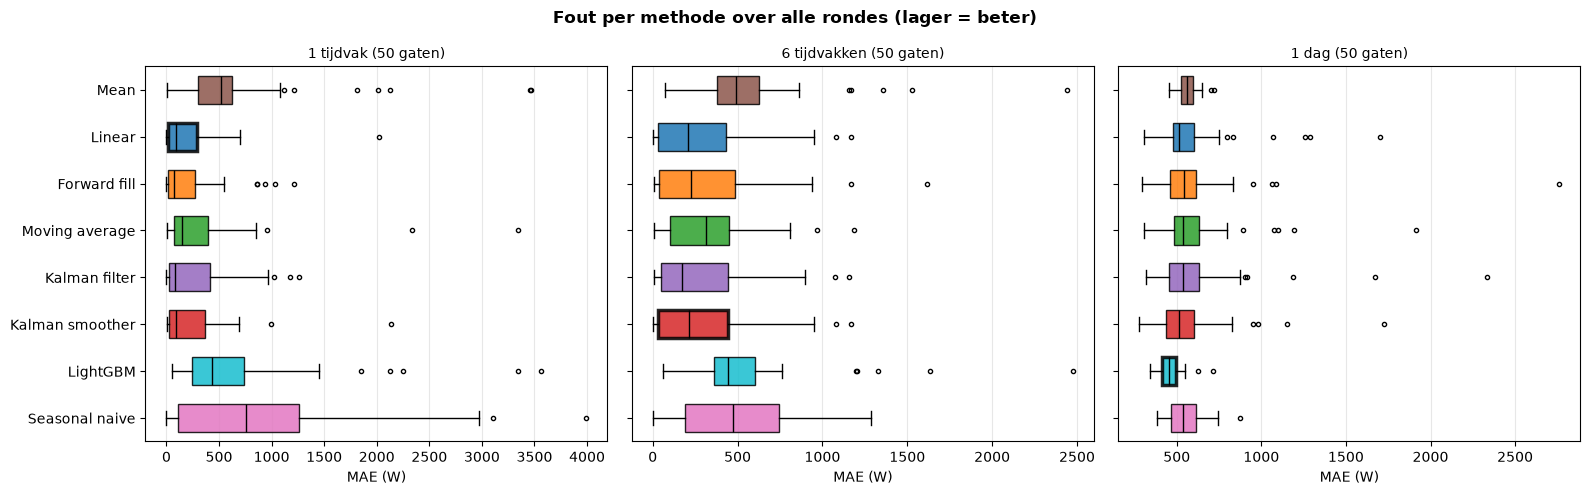

In [39]:
fig, assen = plt.subplots(1, 3, figsize=(16, 5))

for ax, lengte in zip(assen, volgorde):
    deel = rondes[rondes["lengte"] == lengte]
    data_per_methode = [deel.loc[deel["methode"] == m, "MAE"].dropna() for m in KLEUREN]

    boxen = ax.boxplot(data_per_methode, vert=False, patch_artist=True, widths=0.6,
                       medianprops={"color": "black"}, flierprops={"markersize": 3})

    for box, methode in zip(boxen["boxes"], KLEUREN):
        box.set_facecolor(KLEUREN[methode])
        box.set_alpha(0.85)
        if methode == ONZE_KEUZE_LENGTE[lengte]:
            box.set_edgecolor("black")
            box.set_linewidth(2.5)

    ax.set_yticks(range(1, len(KLEUREN) + 1), list(KLEUREN) if ax is assen[0] else [""] * len(KLEUREN))
    ax.invert_yaxis()
    ax.set_title(f"{lengte} ({aantal_gaten[lengte]} gaten)", fontsize=10)
    ax.set_xlabel("MAE (W)")
    ax.grid(axis="x", alpha=0.3)

fig.suptitle("Fout per methode over alle rondes (lager = beter)", fontweight="bold")
plt.tight_layout()
plt.show()

4.9 Blijft de winnaar per ronde hetzelfde?

> Per ronde de gemiddelde MAE van elke methode. Lopen de lijnen door elkaar, dan hangt de winnaar af van welke gaten er toevallig gekozen zijn. Blijft één kleur steeds onderaan, dan is die methode overtuigend de beste

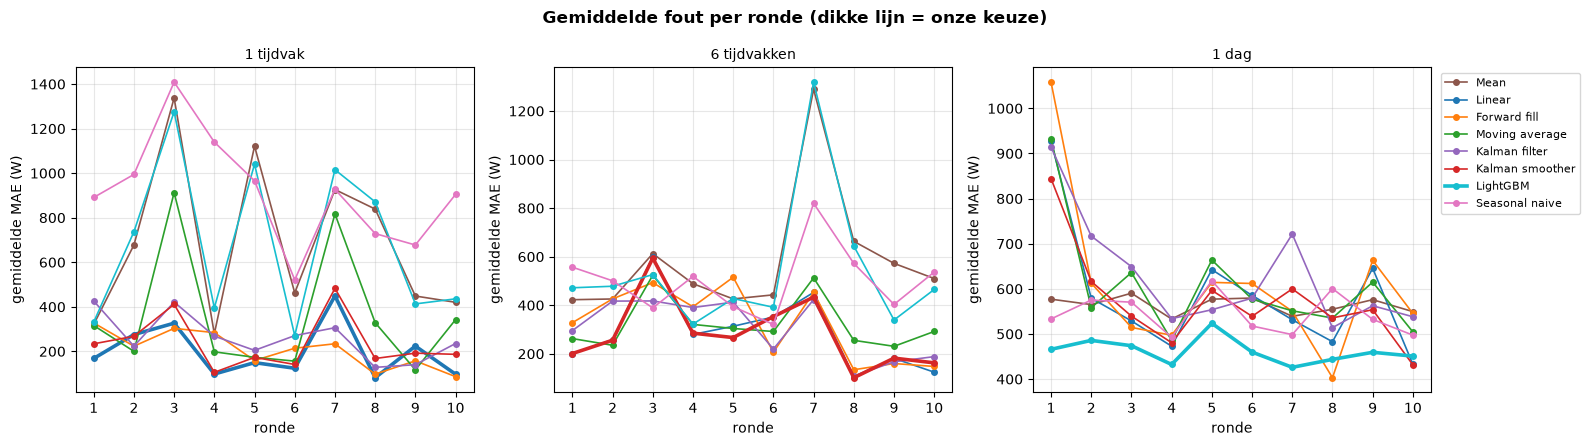

In [40]:
fig, assen = plt.subplots(1, 3, figsize=(16, 4.5))

per_ronde = rondes.groupby(["lengte", "ronde", "methode"])["MAE"].mean()

for ax, lengte in zip(assen, volgorde):
    for methode, kleur in KLEUREN.items():
        lijn = per_ronde.loc[lengte].xs(methode, level="methode")
        dik = 2.6 if methode == ONZE_KEUZE_LENGTE[lengte] else 1.2
        ax.plot(lijn.index, lijn.values, color=kleur, lw=dik, marker="o", ms=4, label=methode)

    ax.set_title(lengte, fontsize=10)
    ax.set_xlabel("ronde")
    ax.set_ylabel("gemiddelde MAE (W)")
    ax.set_xticks(range(1, RONDES + 1))
    ax.grid(alpha=0.3)

assen[-1].legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
fig.suptitle("Gemiddelde fout per ronde (dikke lijn = onze keuze)", fontweight="bold")
plt.tight_layout()
plt.show()

4.10 Is het verschil met de andere methodes toeval?

> Per lengte vergelijken we onze keuze met elke andere methode **op precies dezelfde gaten**. De Wilcoxon-test kijkt of onze keuze op die gaten structureel een lagere fout heeft, of dat het verschil ook door toeval kan komen
>
> **p-waarde kleiner dan 0,05**: het verschil is waarschijnlijk geen toeval. **Groter dan 0,05**: met deze gaten kun je niet zeggen dat de ene methode beter is dan de andere
>
> "Onze keuze beter bij" is het percentage gaten waar onze keuze een lagere fout had dan de andere methode
>
> Demšar raadt deze test aan om twee methodes eerlijk te vergelijken over meerdere testsets, omdat hij niet aanneemt dat de fouten normaal verdeeld zijn

> Bron: Demšar (2006), [Statistical Comparisons of Classifiers over Multiple Data Sets](https://jmlr.org/papers/v7/demsar06a.html), Journal of Machine Learning Research 7, 1–30

In [41]:
from scipy.stats import wilcoxon

vergelijking = []

for lengte in volgorde:
    deel = rondes[rondes["lengte"] == lengte].pivot(index="gat", columns="methode", values="MAE").dropna()
    keuze = ONZE_KEUZE_LENGTE[lengte]

    for andere in KLEUREN:
        if andere == keuze:
            continue

        verschil = deel[keuze] - deel[andere]

        #Test kan niet als alle verschillen 0 zijn
        try:
            p = wilcoxon(deel[keuze], deel[andere]).pvalue
        except ValueError:
            p = np.nan

        vergelijking.append({"lengte": lengte,
                             "onze keuze": keuze,
                             "tegen": andere,
                             "MAE onze keuze": round(deel[keuze].mean(), 1),
                             "MAE andere": round(deel[andere].mean(), 1),
                             "onze keuze beter bij": f"{(verschil < 0).mean() * 100:.0f}%",
                             "p-waarde": round(p, 4),
                             "geen toeval (p < 0,05)": "ja" if p < 0.05 else "nee"})

pd.DataFrame(vergelijking).set_index(["lengte", "onze keuze", "tegen"])

MAE onze keuze  MAE andere  \
lengte       onze keuze      tegen                                         
1 tijdvak    Linear          Mean                      199.3       683.3   
                             Forward fill              199.3       208.7   
                             Moving average            199.3       356.1   
                             Kalman filter             199.3       262.4   
                             Kalman smoother           199.3       236.2   
                             LightGBM                  199.3       678.6   
                             Seasonal naive            199.3       915.9   
6 tijdvakken Kalman smoother Mean                      283.5       585.4   
                             Linear                    283.5       286.7   
                             Forward fill              283.5       325.7   
                             Moving average            283.5       322.9   
                             Kalman filter             283.5       304.0   
                             LightGBM                  283.5       538.4   
                             Seasonal naive            283.5       501.2   
1 dag        LightGBM        Mean                      461.8       564.4   
                             Linear                    461.8       584.5   
                             Forward fill              461.8       604.9   
                             Moving average            461.8       607.2   
                             Kalman filter             461.8       628.6   
                             Kalman smoother           461.8       575.2   
                             Seasonal naive            461.8       543.8   

                                             onze keuze beter bij  p-waarde  \
lengte       onze keuze      tegen                                            
1 tijdvak    Linear          Mean                             84%    0.0000   
                             Forward fill                     56%    0.4901   
                             Moving average                   66%    0.0043   
                             Kalman filter                    60%    0.1032   
                             Kalman smoother                  64%    0.0196   
                             LightGBM                         86%    0.0000   
                             Seasonal naive                   82%    0.0000   
6 tijdvakken Kalman smoother Mean                             80%    0.0000   
                             Linear                           56%    0.2866   
                             Forward fill                     70%    0.0275   
                             Moving average                   78%    0.0040   
                             Kalman filter                    70%    0.0166   
                             LightGBM                         78%    0.0000   
                             Seasonal naive                   80%    0.0000   
1 dag        LightGBM        Mean                             96%    0.0000   
                             Linear                           73%    0.0000   
                             Forward fill                     76%    0.0000   
                             Moving average                   78%    0.0000   
                             Kalman filter                    82%    0.0000   
                             Kalman smoother                  78%    0.0000   
                             Seasonal naive                   94%    0.0000   

                                             geen toeval (p < 0,05)  
lengte       onze keuze      tegen                                   
1 tijdvak    Linear          Mean                                ja  
                             Forward fill                       nee  
                             Moving average                      ja  
                             Kalman filter                      nee  
                             Kalman smoother               

4.11 Conclusie rondes

> *Invullen na het runnen.* Punten om op te letten:
>
> - Is onze keuze per lengte de methode met de laagste gemiddelde fout (4.6) en de beste gemiddelde plek (4.7)?
> - Staat de dikke lijn in 4.9 in elke ronde onderaan, of wisselt het?
> - Wint onze keuze in 4.10 van de andere methodes met p < 0,05? Bij "nee" tegen een methode zijn die twee op deze data niet van elkaar te onderscheiden. Dan is het argument voor onze keuze iets anders, zoals rekentijd of hoe logisch de vorm is (stap 3)
> - Let bij 1 tijdvak op dat Linear en Kalman smoother vaak bijna gelijk scoren: bij één ontbrekend punt doen ze allebei ongeveer hetzelfde